# Which metals the study tracks, and why

The metal list is a union of two screens, either sufficient (see `rules/metals.smk`):

- **policy** — on the EU CRMA strategic list (Annex I of Regulation (EU)
  2024/1252; all 34 Annex II rows are transcribed into
  `data/metal_screen_policy.csv` from `data/source/EU_2024_1252.pdf`, and the
  Annex I subset admits) *and* identified as a foreground material of a technology
  in this set.
- **literature** — energy-transition-led demand reaching `metals.threshold` of
  projected primary production capacity in 2050 (Bieuville et al. 2026,
  `build/metals/literature_screen.csv`). An exposure measure rather than a
  shortage test — the shortage verdict is the study’s own, in `rules/compare.smk`.

Everything drawn here is read straight off `build/metals/*.csv`; the screens are
applied and reconciled against `data/mineral_info.csv` by
`reconcile_metal_selection`, which raises rather than reporting a disagreement, so
a figure here can only ever show a list the workflow has already agreed with.

Run by the `visualise_metal_selection` snakemake rule, or interactively (paths then
resolve relative to the repo root).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

# Snakemake runs this from the repo root, an interactive session from notebooks/;
# neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 -- needs the path above
from utils import get_mineral_groups  # noqa: E402
from info_schemas import (  # noqa: E402
    MetalExclusion,
    MetalSelection,
    MineralInfo,
    PolicyDesignation,
    PolicyScreen,
    ThresholdSensitivity,
)

try:
    paths = {
        "selection": snakemake.input.selection,  # type: ignore
        "sensitivity": snakemake.input.sensitivity,  # type: ignore
        "policy": snakemake.input.policy,  # type: ignore
        "excluded": snakemake.input.excluded,  # type: ignore
        "mineral_info": snakemake.input.mineral_info,  # type: ignore
        "figures": snakemake.output.figures,  # type: ignore
    }
    threshold = snakemake.params.threshold  # type: ignore
    thresholds = list(snakemake.params.thresholds)  # type: ignore
    metals_style = dict(snakemake.params.metals_style)  # type: ignore
    mineral_groups = dict(snakemake.params.mineral_groups)  # type: ignore
    style = dict(snakemake.params.plotting)  # type: ignore
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        config = yaml.safe_load(f)
    threshold = config["metals"]["threshold"]
    thresholds = config["metals"]["sensitivity_thresholds"]
    metals_style = config["metals"]["plotting"]
    mineral_groups = get_mineral_groups(config, repo / "data/mineral_info.csv")
    style = config["plotting"]
    paths = {
        "selection": repo / "build/metals/selection.csv",
        "sensitivity": repo / "build/metals/threshold_sensitivity.csv",
        "policy": repo / "data/metal_screen_policy.csv",
        "excluded": repo / "data/metal_excluded.csv",
        "mineral_info": repo / "data/mineral_info.csv",
        "figures": repo / "build/metals/figures",
    }

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
group_nice = {g: info["nice_name"] for g, info in mineral_groups.items()}
plotting.apply_style(style)

panel = metals_style["panel"]
screen_color = metals_style["screen_color"]
ink = style["ink"]

In [2]:
selection = pd.read_csv(paths["selection"]).set_index(MetalSelection.metal)
sensitivity = pd.read_csv(paths["sensitivity"])
policy = pd.read_csv(paths["policy"])
excluded = pd.read_csv(paths["excluded"]).set_index(MetalExclusion.metal)
mineral_info = pd.read_csv(paths["mineral_info"])


def screen_of(row):
    """Which screen earns a metal its place: one, the other, or both.

    Passing both is the stronger inclusion, so it takes its own ink rather than
    being drawn twice — which is the whole reason the two screen tables are
    allowed to overlap.
    """
    if row[MetalSelection.passes_policy] and row[MetalSelection.passes_literature]:
        return "both"
    if row[MetalSelection.passes_policy]:
        return "policy"
    if row[MetalSelection.passes_literature]:
        return "literature"
    return "neither"


selection["screen"] = selection.apply(screen_of, axis=1)

# End-use group per metal, for the metals the study actually tracks.
groups = mineral_info.set_index(MineralInfo.mineral)[MineralInfo.group]
selection["group"] = groups.reindex(selection.index).map(group_nice)

screen_nice = {
    "policy": "CRMA list only",
    "literature": "Literature screen only",
    "both": "Both screens",
    "neither": "Neither",
}

print(
    f"{selection[MetalSelection.selected].sum()} metals selected, "
    f"{selection[MetalSelection.in_study].sum()} tracked, "
    f"{len(excluded)} excluded on purpose."
)
selection["screen"].value_counts().rename("metals").to_frame()

26 metals selected, 24 tracked, 5 excluded on purpose.


,metals
screen,
both,9
literature,9
policy,8
neither,3


## The two screens

One point per candidate metal. The y axis is the literature screen itself —
transition-led demand over projected primary capacity — and the x axis is how much
of that metal's total demand the transition is, i.e. how much of the pressure the
scenarios in this study could ever reach.

The horizontal line is `metals.threshold`. Colour is which screen earns the metal
its place, and nothing else; metals below the line and off the CRMA list are the
ones the study does not track.

Read the top-right corner as *this study's problem* and the bottom-left as *not
ours*. Tellurium sits high and on neither annex, which is why the union: the
CRMA lists are political-economic indices, not statements about supply
adequacy.

no literature-screen value (not among Bieuville's 32): ['Graphite', 'Iridium', 'Palladium', 'Platinum']


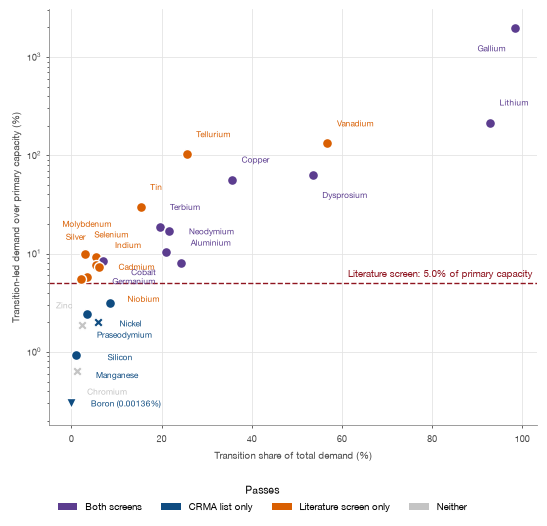

In [3]:
# Only metals the screen's source covers can be placed: the four the paper's 32
# leave out (graphite, iridium, platinum, palladium) have no y value at all and
# are listed under the figure instead of being drawn at a made-up height.
placed = selection[selection[MetalSelection.demand_over_capacity].notna()].copy()
unplaced = selection.index.difference(placed.index)

# Boron is four orders of magnitude below the next metal, so it is drawn at the
# floor and carries its real value in its name rather than stretching the axis.
floor = metals_style["floor_percent"]
true_value = placed[MetalSelection.demand_over_capacity] * 100
below_floor = true_value < floor

scatter_panel = metals_style["scatter_panel"]
fig, ax = plt.subplots(figsize=(scatter_panel["width"], scatter_panel["height"]))

frame = pd.DataFrame(
    {
        "x": placed[MetalSelection.transition_share] * 100,
        "y": true_value.clip(lower=floor),
    },
    index=placed.index,
)
colors = {metal: screen_color[s] for metal, s in placed["screen"].items()}
# A cross for a metal that is declared and deliberately not tracked, so an
# exclusion never looks like an omission; a downward triangle for one pinned to
# the floor.
markers = {
    metal: (
        "v"
        if below_floor[metal]
        else ("X" if row[MetalSelection.excluded_on_purpose] else "o")
    )
    for metal, row in placed.iterrows()
}
names = {
    metal: (f"{metal} ({true_value[metal]:.3g}%)" if below_floor[metal] else metal)
    for metal in frame.index
}

plotting.plain_points(ax, frame, colors, markers, size=52, ink=ink)
ax.axhline(
    threshold * 100,
    color=metals_style["threshold_line_color"],
    linestyle="--",
    linewidth=1.0,
    zorder=1,
)
ax.annotate(
    f"Literature screen: {threshold:.1%} of primary capacity",
    xy=(0.99, threshold * 100),
    xycoords=("axes fraction", "data"),
    xytext=(0, 3),
    textcoords="offset points",
    ha="right",
    va="bottom",
    fontsize=7.0,
    color=metals_style["threshold_line_color"],
)

plotting.style_scatter(
    ax,
    style,
    # No title or subtitle: the caption is written where the figure is
    # published, and the source of the y axis belongs in it.
    title=None,
    xlabel="Transition share of total demand (%)",
    ylabel="Transition-led demand over primary capacity (%)",
    log_y=True,
)
ax.set_ylim(bottom=floor * 0.6)
plotting.label_points(ax, frame, names, colors, metals_style["label"])

# Outside the axes: the crowd of literature-only metals sits in the lower left, which
# is where a legend would otherwise go.
legend = ax.legend(
    handles=plotting.patch_handles(
        ["both", "policy", "literature", "neither"], screen_color, screen_nice
    ),
    loc="upper left",
    bbox_to_anchor=(0.0, -0.12),
    ncol=4,
    frameon=False,
    title="Passes",
)
plotting.save_figure(fig, figures_dir, "metal_screens", style, extra_artists=(legend,))

print("no literature-screen value (not among Bieuville's 32):", list(unplaced))

## The literature screen as a ranking

The same y axis, laid flat. This is the figure the threshold is chosen on: it shows
how far each metal sits from the line, and therefore which metals the choice of cut
actually decides.

Cadmium (7.4%), indium (7.7%) and aluminium (8.1%) cluster just above it. That
matters for cadmium in particular, because CdTe is a modelled sub-technology — a
cut above ~7% would drop the metal a solar scenario is there to interrogate.

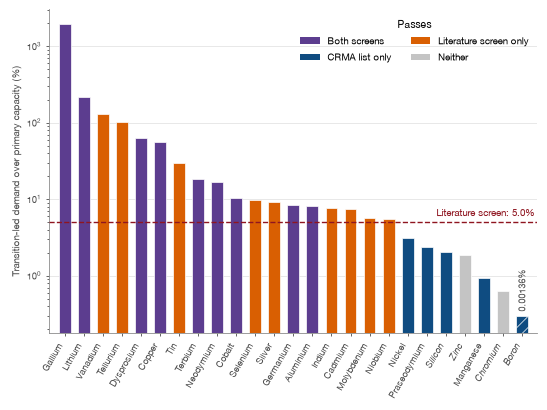

In [4]:
ranked = placed.sort_values(MetalSelection.demand_over_capacity, ascending=False)
ranked_true = ranked[MetalSelection.demand_over_capacity] * 100
ranked_below = ranked_true < floor

fig, ax = plt.subplots(figsize=(style["metal_axis"]["width"], panel["height"]))
positions = np.arange(len(ranked))

bars = ax.bar(
    positions,
    ranked_true.clip(lower=floor),
    width=style["metal_axis"]["bar_width"],
    color=[screen_color[s] for s in ranked["screen"]],
    edgecolor=style["bar"]["edge_color"],
    linewidth=style["bar"]["edge_width"],
    zorder=2,
)
# A bar pinned to the floor is hatched and carries its real value, so it cannot be
# read as "just under the smallest threshold tested".
for bar, metal in zip(bars, ranked.index):
    if not ranked_below[metal]:
        continue
    bar.set_hatch("///")
    ax.annotate(
        f"{ranked_true[metal]:.3g}%",
        xy=(bar.get_x() + bar.get_width() / 2, floor),
        xytext=(0, 3),
        textcoords="offset points",
        ha="center",
        va="bottom",
        rotation=90,
        fontsize=6.5,
        color=ink["secondary"],
    )

# Only the chosen cut is drawn. The other thresholds are what the sensitivity
# matrix below is for, and on a log axis spanning three decades they would sit on
# top of this line rather than beside it.
ax.axhline(
    threshold * 100,
    color=metals_style["threshold_line_color"],
    linestyle="--",
    linewidth=1.0,
    zorder=3,
)
ax.annotate(
    f"Literature screen: {threshold:.1%}",
    xy=(0.995, threshold * 100),
    xycoords=("axes fraction", "data"),
    xytext=(0, 3),
    textcoords="offset points",
    ha="right",
    va="bottom",
    fontsize=7.0,
    color=metals_style["threshold_line_color"],
)

plotting.category_axis(
    ax,
    dict(zip(ranked.index, positions.astype(float))),
    {metal: metal for metal in ranked.index},
    style,
    "metal_axis",
)
for tick, metal in zip(ax.get_xticklabels(), ranked.index):
    tick.set_rotation(60)
    tick.set_ha("right")
    if not ranked.loc[metal, MetalSelection.in_study]:
        tick.set_color(metals_style["excluded_color"])
        tick.set_style("italic")

plotting.style_panel(
    ax,
    style,
    title=None,
    ylabel="Transition-led demand over primary capacity (%)",
    log=True,
)
ax.set_ylim(bottom=floor * 0.6)
legend = ax.legend(
    handles=plotting.patch_handles(
        ["both", "policy", "literature", "neither"], screen_color, screen_nice
    ),
    loc="upper right",
    frameon=False,
    ncol=2,
    title="Passes",
)
plotting.save_figure(
    fig, figures_dir, "literature_screen_ranked", style, extra_artists=(legend,)
)

## What the threshold is worth

The threshold sensitivity, as a matrix: for each cut tested, whether the union of
the two screens still selects the metal. Metals whose row is constant are decided
by something other than the cut — most of them by the CRMA list, which is most of
why the union is robust where the literature screen alone would not be.

This is the whole argument for 5%. It costs one plot and says more than a
justification would.

decided by the threshold: ['Selenium', 'Silver', 'Indium', 'Cadmium', 'Molybdenum', 'Niobium']


,passes_literature,selected
threshold,,
0.025,19,26
0.050,18,26
0.075,15,23
0.100,10,20


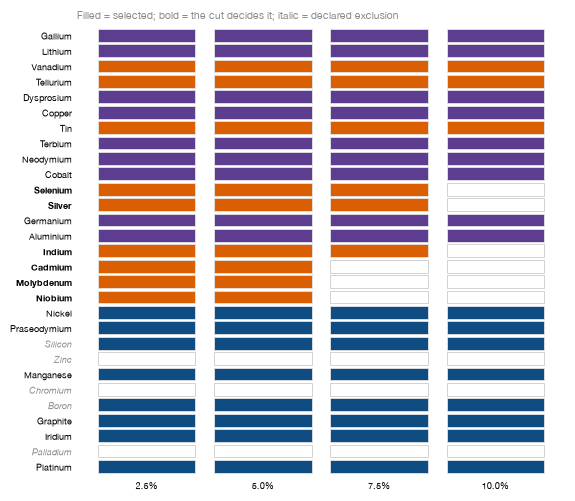

In [5]:
grid = sensitivity.pivot_table(
    index=ThresholdSensitivity.metal,
    columns=ThresholdSensitivity.threshold,
    values=ThresholdSensitivity.selected,
    aggfunc="first",
)
order = (
    selection[MetalSelection.demand_over_capacity]
    .reindex(grid.index)
    .sort_values(ascending=False)
    .index
)
grid = grid.reindex(order)
decided_by_threshold = grid.index[grid.nunique(axis=1) > 1]

fig, ax = plt.subplots(figsize=(panel["width"], 0.16 * len(grid) + 1.2))
for column, level in enumerate(grid.columns):
    for row, metal in enumerate(grid.index):
        selected = bool(grid.iat[row, column])
        ax.add_patch(
            plt.Rectangle(
                (column - 0.42, row - 0.42),
                0.84,
                0.84,
                facecolor=screen_color[selection.loc[metal, "screen"]]
                if selected
                else ink["surface"],
                edgecolor=ink["grid"] if selected else ink["muted"],
                linewidth=0.6,
                alpha=1.0 if selected else 0.45,
            )
        )

ax.set_xlim(-0.6, len(grid.columns) - 0.4)
ax.set_ylim(-0.6, len(grid) - 0.4)
ax.invert_yaxis()
ax.set_xticks(range(len(grid.columns)))
ax.set_xticklabels([f"{level:.1%}" for level in grid.columns])
ax.set_yticks(range(len(grid)))
ax.set_yticklabels(grid.index)
for tick, metal in zip(ax.get_yticklabels(), grid.index):
    if metal in decided_by_threshold:
        tick.set_weight("bold")
    if not selection.loc[metal, MetalSelection.in_study]:
        tick.set_color(metals_style["excluded_color"])
        tick.set_style("italic")
ax.tick_params(length=0)
ax.grid(False)
ax.spines[["top", "right", "left", "bottom"]].set_visible(False)

# The note says how to read the marks, so it is the key rather than a title.
ax.annotate(
    "Filled = selected; bold = the cut decides it; italic = declared exclusion",
    xy=(0.0, 1.0),
    xycoords="axes fraction",
    xytext=(0, 5),
    textcoords="offset points",
    color=ink["muted"],
)
plotting.save_figure(fig, figures_dir, "threshold_sensitivity", style)

counts = sensitivity.groupby(ThresholdSensitivity.threshold)[
    [ThresholdSensitivity.passes_literature, ThresholdSensitivity.selected]
].sum()
print("decided by the threshold:", list(decided_by_threshold))
counts

## The policy screen

Annex II of Regulation (EU) 2024/1252 lists 34 critical raw materials; Annex I
names 17 of them strategic as well. The regulation lists *raw materials*, not
metals — one entry can be a rock (`bauxite/alumina/aluminium`), a family
(`platinum group metals`) or a grade (`nickel — battery grade`) — so
`data/metal_screen_policy.csv` records this study's reading of each entry and the
technology that justifies it.

The screen admits the Annex I entries: Annex I scores forecast demand growth and
the difficulty of raising production, Annex II scores economic importance against
supply risk with no demand term. Critical-only entries keep their reading below
without admitting on it, so what restricting to Annex I gives up is on the record
— one metal, which the literature screen takes anyway.

In [6]:
reaches = policy[PolicyScreen.minerals].notna()
strategic = policy[PolicyScreen.designation] == PolicyDesignation.strategic
summary = pd.DataFrame(
    {
        "Annex II entries": [len(policy)],
        "of which strategic (Annex I)": [int(strategic.sum())],
        "strategic, reaching a technology here": [int((strategic & reaches).sum())],
        "metals they admit": [int(selection[MetalSelection.passes_policy].sum())],
        "critical-only claims, not admitted": [int((~strategic & reaches).sum())],
    },
    index=["count"],
)
display(summary)

policy.loc[reaches, [
    PolicyScreen.raw_material,
    PolicyScreen.designation,
    PolicyScreen.minerals,
    PolicyScreen.technology,
]].reset_index(drop=True)

,Annex II entries,of which strategic (Annex I),"strategic, reaching a technology here",metals they admit,"critical-only claims, not admitted"
count,34,18,14,17,1


,raw_material,designation,minerals,technology
0,bauxite/alumina/aluminium,strategic,Aluminium,grid_hv_ac; grid_dc; grid_distribution; onshor...
1,boron,strategic,Boron,onshore_wind; offshore_wind
2,cobalt,strategic,Cobalt,ev_battery; grid_battery
3,copper,strategic,Copper,grid_hv_ac; grid_dc; grid_distribution; onshor...
4,gallium,strategic,Gallium,utility_solar; rooftop_solar
5,germanium,strategic,Germanium,utility_solar; rooftop_solar
6,heavy rare earth elements,strategic,Dysprosium; Terbium,onshore_wind; offshore_wind; ev_motor
7,light rare earth elements,strategic,Neodymium; Praseodymium,onshore_wind; offshore_wind; ev_motor
8,lithium,strategic,Lithium,ev_battery; grid_battery
9,manganese,strategic,Manganese,ev_battery; grid_battery; onshore_wind; offsho...


## The list, and what is deliberately not on it

`build/metals/selection.csv` in full, then the declared exclusions. The exclusions
are the point of the module: `reconcile_metal_selection` raises when a metal passes
a screen, or is bought by name in `data/bom_material_info.csv`, without a row in
`data/mineral_info.csv`. Silicon, boron and titanium pass the policy screen and are
held out on purpose; zinc, cerium, zirconium and barium are bought by a bill of
materials and pass neither screen; palladium is designated by the Annex II PGM
entry and reaches no technology.

That check is what catches a foreground purchase being made and then not counted.
Cadmium, tellurium, indium and selenium reach the study only through the thin-film
PV cells, so without it a solar scenario could move all four and score as though it
moved nothing at all.

In [7]:
shown = selection[
    [
        "screen",
        MetalSelection.designation,
        MetalSelection.demand_over_capacity,
        MetalSelection.transition_share,
        MetalSelection.selected,
        MetalSelection.in_study,
        MetalSelection.excluded_on_purpose,
        "group",
    ]
].copy()
display(shown.style.format({
    MetalSelection.demand_over_capacity: "{:.3f}",
    MetalSelection.transition_share: "{:.3f}",
}, na_rep="—"))

excluded[[MetalExclusion.considered_because, MetalExclusion.reason]]

,screen,designation,demand_over_capacity,transition_share,selected,in_study,excluded_on_purpose,group
metal,,,,,,,,
Gallium,both,strategic,19.685,0.984,True,True,False,Semiconductor
Lithium,both,strategic,2.155,0.928,True,True,False,Battery
Vanadium,literature,—,1.322,0.568,True,True,False,Bulk/dual-use
Tellurium,literature,—,1.026,0.255,True,True,False,Semiconductor
Dysprosium,both,strategic,0.635,0.535,True,True,False,Magnet REEs
Copper,both,strategic,0.566,0.356,True,True,False,Grid/conductor
Tin,literature,—,0.298,0.153,True,True,False,Contacts/solder
Terbium,both,strategic,0.187,0.197,True,True,False,Magnet REEs
Neodymium,both,strategic,0.169,0.218,True,True,False,Magnet REEs


,considered_because,reason
metal,,
Silicon,"Passes the policy screen: Annex I strategic (""...",Held out deliberately. Silicon's constraint is...
Boron,"Passes the policy screen: Annex I strategic (""...",Held out deliberately. Boron is the one policy...
Chromium,Carried by data/mineral_intensity_literature.c...,"On neither screen: not a CRMA raw material, an..."
Zinc,Carried by data/mineral_intensity_literature.c...,"On neither screen: not a CRMA raw material, 0...."
Palladium,Has a column in data/mineral_intensity_literat...,The literature column is empty — no source in ...


## Graphite is tracked at battery grade

One metal is tracked at a single grade rather than whole, so its scope is worth
stating beside the screens that admitted it.

- **Supply** is the IEA `Graphite - Battery grade` series, which covers spherical
  purified natural and synthetic alike. IEA's *demand* sheet is explicitly all
  grades, so it is not used for graphite; the two are on different bases inside the
  same workbook.
- **Demand** is the anode. Both sides are measured at the anode-ready stage, so each
  route's yield losses — flake to spherical, coke to graphitised — sit upstream of
  the comparison and the ratio does not depend on which route supplies the anode.
- **Other-sector demand** is the Li-ion slice of graphite's own Material System
  Analysis (8% of EU use), 5.2 kt/yr, 135 kt over the window, 0.7% of allocated
  supply at the GDP principle. The refractory, foundry, friction and lubricant
  slices are `off_grade` and charged to nobody, because they are a different
  commodity. Its known weakness is the flat hold: one 2016 reference year carried
  across the window, for a use that is growing.
- **Scaling** graphite means a graphitisation line rather than a mine, which is why
  `data/mineral_info.csv` types it `Primary with synthetic option` and the figures
  file it with the by-products.